In [1]:
from src.slm_initialise import slm_initialise
from src.utils import *
%load_ext autoreload
%autoreload 2

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [2]:
fs = slm_initialise(force=True,verbose=True)

An error occurred: 'NoneType' object has no attribute 'close'
Initializing pyglet... success
Searching for window with display_number=1... success
Creating window... [Errno 2] No such file or directory: 'C:\\Users\\QC\\Envs\\SLM_new\\Lib\\site-packages\\slmsuite\\hardware\\..\\..\\docs\\source\\static\\slmsuite-notext-16x16.png'
success
TLCameraSDK initializing... success
Looking for cameras... success
ThorCam sn '12975' initializing... success


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


array([[2, 2, 3, ..., 2, 1, 3],
       [1, 3, 3, ..., 2, 1, 2],
       [3, 1, 2, ..., 2, 2, 2],
       ...,
       [1, 3, 3, ..., 2, 3, 2],
       [3, 3, 2, ..., 2, 1, 2],
       [2, 3, 2, ..., 3, 2, 2]], dtype=uint16)

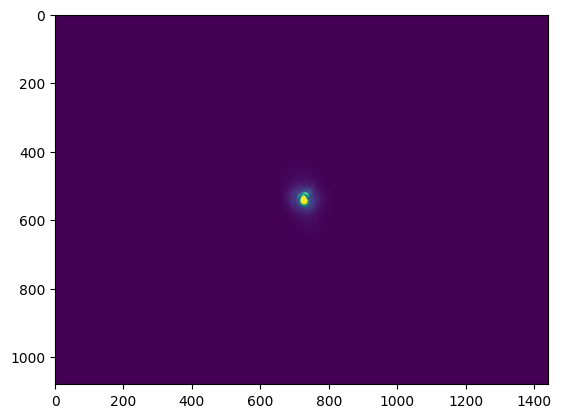

In [3]:
plot_cam(fs,phase="zero")

In [4]:
calibrate(fs,vendor = True,refresh = False)

smooth:   0%|          | 0/16 [00:00<?, ?it/s]

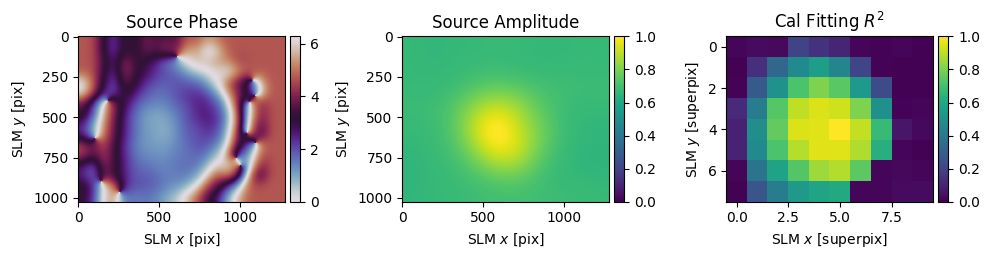

In [5]:
sp_calibrate(fs,refresh=False)

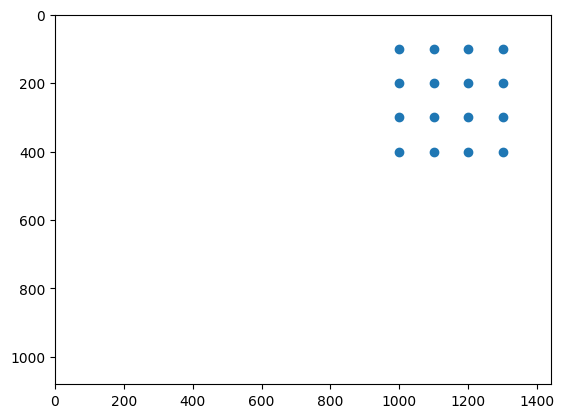

c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\holography\algorithms\_hologram.py:377: UserWarning: Hologram target shape (1024, 1280) is not a power of 2; consider using .get_padded_shape() to pad to powers of 2 and speed up FFT computation. While some FFT solvers support other prime powers (3, 5, 7, ...), literature suggests that GPU support is best for powers of 2.
  warnings.warn(


  0%|          | 0/30 [00:00<?, ?it/s]

testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing shape :  (1080, 1440)
testing sh

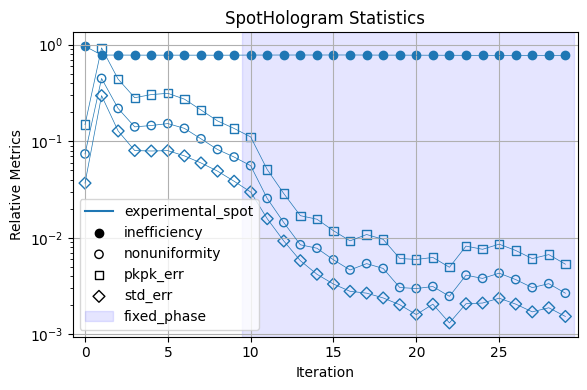

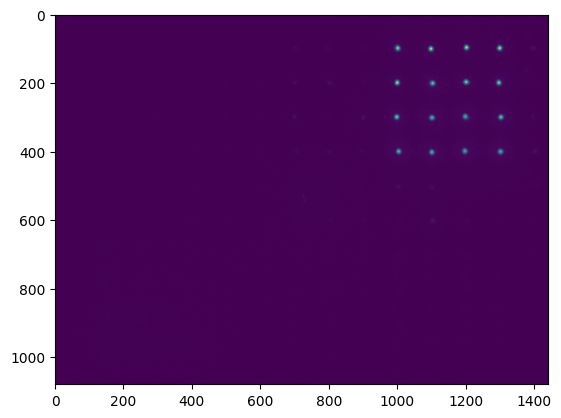

In [6]:
holo = create_tweezers(fs)

array([[5, 6, 6, ..., 4, 5, 5],
       [6, 6, 5, ..., 4, 4, 6],
       [6, 6, 7, ..., 5, 4, 5],
       ...,
       [3, 3, 4, ..., 7, 4, 4],
       [4, 3, 5, ..., 6, 6, 4],
       [5, 4, 3, ..., 6, 4, 5]], dtype=uint16)

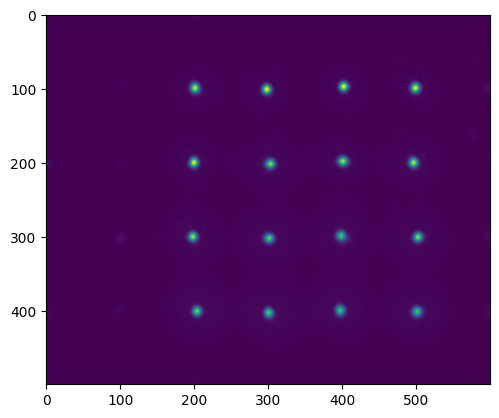

In [7]:
plot_cam(fs,limits=(slice(0, 500), slice(800, 1400)))

array([[2, 2, 2, ..., 2, 2, 2],
       [2, 2, 3, ..., 2, 2, 2],
       [3, 2, 3, ..., 3, 2, 2],
       ...,
       [3, 2, 2, ..., 3, 4, 3],
       [3, 3, 3, ..., 4, 4, 4],
       [4, 3, 3, ..., 4, 3, 3]], dtype=uint16)

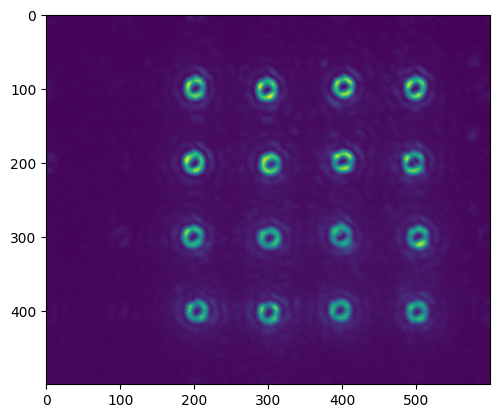

In [8]:
plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase,limits=(slice(0, 500), slice(800, 1400)))

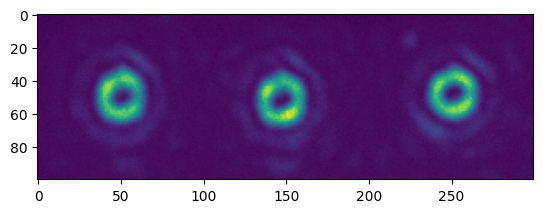

In [10]:
img = plot_cam(fs,phase = bottle_beam_phase(fs)+holo.phase,limits=(slice(50, 150), slice(950, 1250)))

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from tifffile import imread
import os

In [140]:
def single_gaussian(x, A, x0, sigma, offset):
    return A * np.exp(-(x - x0)**2 / (2 * sigma**2)) + offset
def dark_trap_model(x, A1, sigma1, A2, sigma2, x0, offset):
    return (A1 * np.exp(-(x - x0)**2 / (2 * sigma1**2))
           - A2 * np.exp(-(x - x0)**2 / (2 * sigma2**2))
           + offset)

In [141]:
# === Analyze trap ===
def analyze_trap(img, trap_type='bright', direction='horizontal'):
    # img = imread(image_path)
    center_y, center_x = np.array(img.shape) // 2
    if direction == 'horizontal':
        x_vals = np.arange(img.shape[1])
        line_data = img[center_y, :]
    elif direction == 'vertical':
        x_vals = np.arange(img.shape[0])
        line_data = img[:, center_x]
    else:
        raise ValueError("direction must be 'horizontal' or 'vertical'")
    # Fit appropriate model
    if trap_type == 'bright':
        model = single_gaussian
        p0 = [line_data.max() - line_data.min(), x_vals[len(x_vals)//2], 10, line_data.min()]
    elif trap_type == 'dark':
        model = dark_trap_model
        A1_guess = line_data.max() - line_data.min()
        A2_guess = A1_guess / 2
        sigma1_guess = 15
        sigma2_guess = 5
        x0_guess = x_vals[len(x_vals)//2]
        offset_guess = line_data.min()
        p0 = [A1_guess, sigma1_guess, A2_guess, sigma2_guess, x0_guess, offset_guess]
    else:
        raise ValueError("trap_type must be 'bright' or 'dark'")
    popt, pcov = curve_fit(model, x_vals, line_data, p0=p0)
    fit_data = model(x_vals, *popt)
    # Plot
    plt.figure(figsize=(8, 4))
    plt.plot(x_vals, line_data, label='Line scan data')
    plt.plot(x_vals, fit_data, 'r--', label='Fit')
    plt.title(f'{trap_type.capitalize()} trap: {direction}')
    plt.xlabel('Pixel position')
    plt.ylabel('Intensity')
    plt.legend()
    plt.tight_layout()
    plt.show()
    return popt

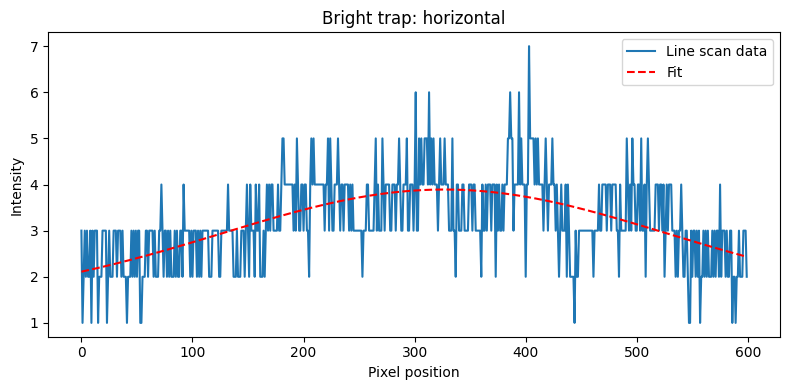

array([  2.42932365, 326.76749731, 201.03548584,   1.4620722 ])

In [142]:
# === Example usage ===
analyze_trap(img, trap_type='bright', direction='horizontal')
# analyze_trap('dark_trap.tif', trap_type='dark', direction='horizontal')

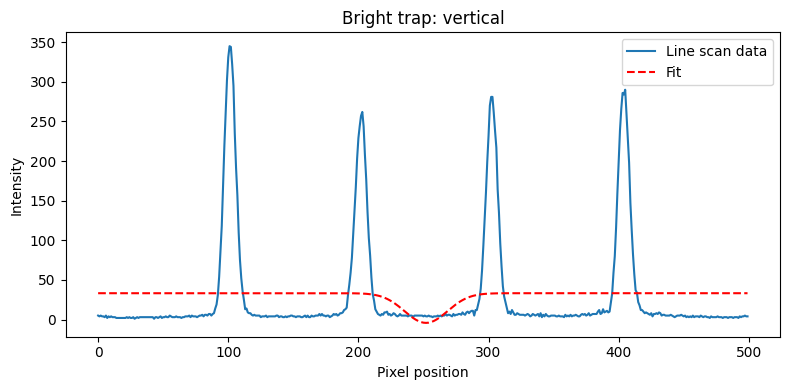

array([-37.45258242, 251.93888747,  16.43819592,  33.23042643])

In [143]:
analyze_trap(img, trap_type='bright', direction='vertical')

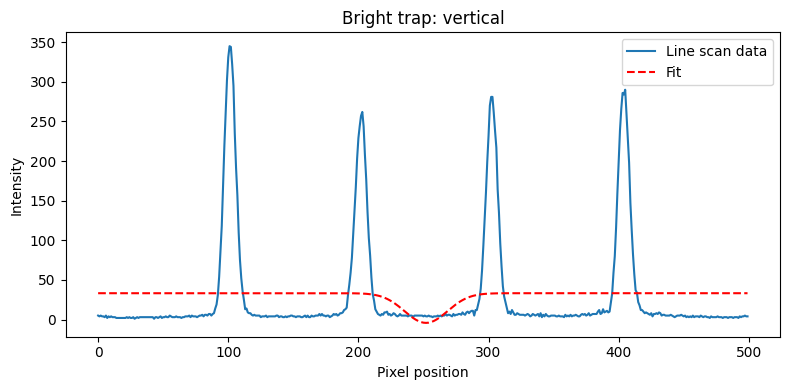

array([-37.45258242, 251.93888747,  16.43819592,  33.23042643])

In [144]:
analyze_trap(img, trap_type='bright', direction='vertical')

In [145]:
analyze_trap(img, trap_type='dark', direction='vertical')

RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 1400.

In [12]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.lines as mlines

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel
from sklearn.model_selection import train_test_split

In [13]:
np.random.seed(17)  # So you can reproduce these results at home
nv = 20  # Number of points in each direction
xv = np.arange(0,img.shape[1])  # x-vector
yv = np.arange(0,img.shape[0])  # y-vector
x, y = np.meshgrid(xv, yv)  # x and y are (nv, nv) matrices
z = img[y,x]

X = np.column_stack((x.reshape(-1), y.reshape(-1)))
Z = z.reshape(-1,1)

In [14]:
guess_l = (2., 1.)  # In general, x and y have different scales
bounds_l = ((1e-1,100.),) * 2  # Same bounds for x and y
guess_n = 1.  # Amount of noise
bounds_n = (1e-20, 10.) # Bounds for noise
kernel = (  # Kernel objects can simply be summed using +
    RBF(length_scale=guess_l, length_scale_bounds=bounds_l)
    + WhiteKernel(noise_level=guess_n, noise_level_bounds=bounds_n)
)

In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Z, test_size=0.95)


In [16]:
gpr = GaussianProcessRegressor(kernel, normalize_y=True )
gpr.fit(X_train, Y_train)

GaussianProcessRegressor(kernel=RBF(length_scale=[2, 1]) + WhiteKernel(noise_level=1),
                         normalize_y=True)

In [17]:
print(gpr.kernel_)

RBF(length_scale=[5.63, 5.83]) + WhiteKernel(noise_level=0.00792)


In [18]:
Zfit, Zstd = gpr.predict(X, return_std=True)
zstd = Zstd.reshape(x.shape)
zfit = Zfit.reshape(x.shape)

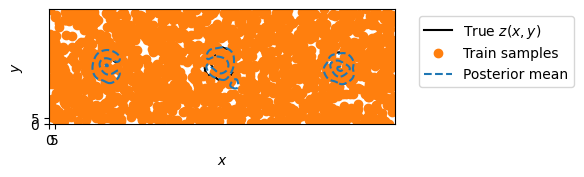

In [19]:
# Set up figure
fig, ax = plt.subplots(figsize=(6., 4.))
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
# ax.set_xlim((-5,5))
# ax.set_ylim((-5,5))
ax.set_aspect('equal')
ax.set_xticks((-5,0,5))
ax.set_yticks((-5,0,5))
ax.grid(False)

# Do the plotting
lev = np.linspace(0.,250.,6)
ax.contour(x,y,z,lev,colors='k')  # Truth
ax.plot(*X_train.T,'o',color="C1")  # Training samples
ax.contour(x, y,zfit, lev, colors='C0', linestyles='dashed')  # Posterior mean

# Legend
truth_line = mlines.Line2D([], [], color='black', label='True $z(x,y)$')
sample_line = mlines.Line2D([], [], color='C1', marker="o", linestyle="none", label='Train samples')
mean_line = mlines.Line2D([], [], color='C0', linestyle="--", label='Posterior mean')
ax.legend(handles=[truth_line, sample_line, mean_line],bbox_to_anchor=(1.05, 1), loc="upper left")

# Write out
plt.tight_layout()
plt.savefig('gpr_posterior_mean.svg')

In [20]:
zfit.shape

(100, 300)

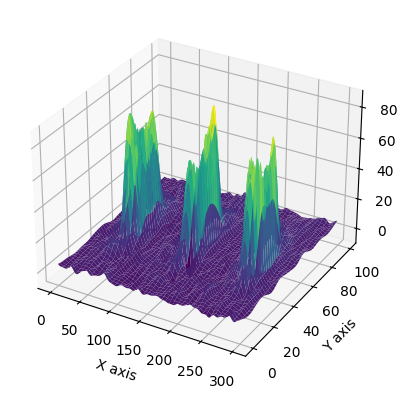

In [21]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot a surface
ax.plot_surface(x, y, zfit, cmap='viridis')

# Add labels
ax.set_xlabel('X axis')
ax.set_ylabel('Y axis')
ax.set_zlabel('Z axis')

# Show the plot
plt.show()

In [22]:
import plotly.graph_objects as go

# Create a 3D surface plot
fig = go.Figure(data=[go.Surface(z=z, x=x, y=y)])

# Customize layout
fig.update_layout(
    title='Interactive 3D Surface Plot',
    scene=dict(
        xaxis_title='X axis',
        yaxis_title='Y axis',
        zaxis_title='Z axis'
    )
)

# Show the plot
fig.show()

In [23]:
import plotly.graph_objects as go

# Create a 3D surface plot
fig = go.Figure(data=[go.Surface(z=zfit, x=x, y=y)])

# Customize layout
fig.update_layout(
    title='Interactive 3D Surface Plot',
    scene=dict(
        xaxis_title='X axis',
        yaxis_title='Y axis',
        zaxis_title='Z axis'
    )
)

# Show the plot
fig.show()

In [ ]:
def twoD_Gaussian(xy, amplitude, xo, yo, sigma_x, sigma_y, theta, offset):
    x, y = xy
    xo = float(xo)
    yo = float(yo)
    a = (np.cos(theta)**2)/(2*sigma_x**2) + (np.sin(theta)**2)/(2*sigma_y**2)
    b = -(np.sin(2*theta))/(4*sigma_x**2) + (np.sin(2*theta))/(4*sigma_y**2)
    c = (np.sin(theta)**2)/(2*sigma_x**2) + (np.cos(theta)**2)/(2*sigma_y**2)
    g = offset + amplitude*np.exp( - (a*((x-xo)**2) + 2*b*(x-xo)*(y-yo)
                            + c*((y-yo)**2)))
    return g.ravel()

In [63]:
h, w = img.shape
data = img.ravel()

x = np.linspace(0, w, w)
y = np.linspace(0, h, h)
x, y = np.meshgrid(x, y)

# initial guess of parameters
initial_guess = (1200, 120, 80, 20, 20, 0, 50)

# find the optimal Gaussian parameters
popt, pcov = curve_fit(twoD_Gaussian, (x, y), data, p0=initial_guess) 

# create new data with these parameters
data_fitted = twoD_Gaussian((x, y), *popt)

RuntimeError: Optimal parameters not found: Number of calls to function has reached maxfev = 1600.

In [62]:
# add some noise to the data and try to fit the data generated beforehand
initial_guess = (3,100,100,20,40,0,10)


popt, pcov = curve_fit(twoD_Gaussian, (x, y), Z, p0=initial_guess)

data_fitted = twoD_Gaussian((x, y), *popt)

fig, ax = plt.subplots(1, 1)
#ax.hold(True) For older versions. This has now been deprecated and later removed
ax.imshow(img.reshape(201, 201), cmap=plt.cm.jet, origin='lower',
    extent=(x.min(), x.max(), y.min(), y.max()))
ax.contour(x, y, data_fitted.reshape(201, 201), 8, colors='w')
plt.show()

ValueError: object too deep for desired array

error: Result from function call is not a proper array of floats.

In [50]:
img.shape

(100, 300)